In [1]:
import pandas as pd
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

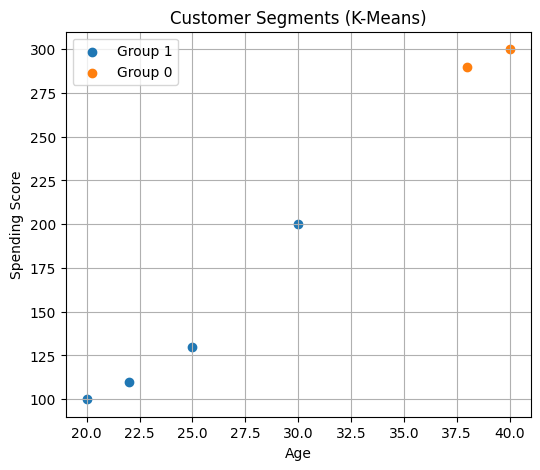

  Customer  Age  Spending  Group
0     Riya   20       100      1
1     Sonu   30       200      1
2     raju   40       300      0
3    raman   22       110      1
4     sita   38       290      0
5     teju   25       130      1


In [4]:
#sample data
data ={
    'Customer':['Riya','Sonu','raju','raman','sita','teju'],
    'Age':[20,30,40,22,38,25],
    'Spending':[100,200,300,110,290,130]
}

df= pd.DataFrame(data)

X =df[['Age','Spending']]

#first normalize each column---------------------------------------------------------------

model = KMeans(n_clusters=2,random_state=42,n_init=10)

#random_state is used for getting same result every time you run the code, if not the clusters may slightly change each time 
#n_init=10, tries total 10 times(keeping more than 10 to avoid slow run of the code) to keep the guess of the leader in each group the perfect so that there becomes best grouping to find the best and stable cluster to refrer in the each group

df['Group']=model.fit_predict(X)   #creates a column called group with either 0 or 1 as value

plt.figure(figsize=(6,5))
for group in df['Group'].unique():   #[0,1] two clusters
    group_data=df[df['Group']==group] #masking
    plt.scatter(group_data['Age'],group_data['Spending'],label=f'Group {group}')

plt.xlabel('Age')
plt.ylabel('Spending Score')
plt.title("Customer Segments (K-Means)")
plt.grid(True)
plt.legend()
plt.show()
print(df)





In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA 


Variance captured by each PCA component:
[99.65  0.35]


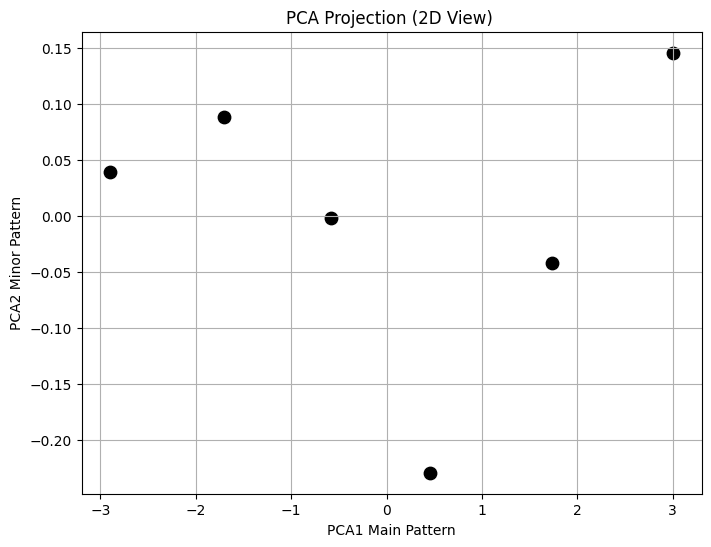

New data with new features:PCA1 PCA2
       PCA1      PCA2
0 -2.901838  0.038962
1 -1.703939  0.088054
2 -0.585677 -0.001447
3  0.452949 -0.229542
4  1.730485 -0.041856
5  3.008020  0.145829


In [9]:
data={
    'age':[25,30,35,40,45,50],
    'income':[30000,40000,50000,60000,70000,80000],
    'spending':[70,60,50,40,30,20],
    'saving':[1000,5000,8000,10000,15000,20000]
}

df=pd.DataFrame(data)


scaler = StandardScaler()

scaled_data=scaler.fit_transform(df)

pca = PCA(n_components=2)
pca_result = pca.fit_transform(scaled_data)

pca_df = pd.DataFrame(pca_result,columns=['PCA1','PCA2'])

explained_variance = pca.explained_variance_ratio_
print("Variance captured by each PCA component:")
print(np.round(explained_variance*100,2))

plt.figure(figsize=(8,6))
plt.scatter(pca_df['PCA1'],pca_df['PCA2'],color='black', s=80)
plt.title("PCA Projection (2D View) ")
plt.xlabel("PCA1 Main Pattern")
plt.ylabel("PCA2 Minor Pattern")
plt.grid(True)
plt.show()

print("New data with new features:PCA1 PCA2")
print(pca_df)